##**Project:** The Backpack Clinic — Field-based dysglycemia triage
##**Module:** CIP02, Autumn 2026
##Owner: D. Shori

# 0. Overview

This notebook answers the three research questions. It loads the frozen
analytic sample from notebook 01 and does not modify it.

| Section | Content |
|---|---|
| 1 | Setup and data |
| 2 | Modelling decisions (handoff items from notebook 01) |
| 3 | **RQ1** — How well do backpack measurements predict dysglycemia? |
| 4 | **RQ2** — How reliable is a positive result in each US county? |
| 5 | **RQ3** — Does the model work equally well for all patients? |
| 6 | Exports for the dashboard |
| 7 | Summary of findings |

**Methods and where they come from.**

| Step | Method | Course block |
|---|---|---|
| Load and inspect | `read_csv`, `info`, `describe`, `isna`, `duplicated` | SW02 — pandas, data cleaning |
| Subgroup tables | `loc` filtering, `groupby().agg()`, `to_csv` | SW02 — pandas; SW03 — storage |
| Figures | matplotlib (subplots, labels, legends, log axis), seaborn (heatmap, KDE), pandas `.plot`, plotly (county map) | SW04 — scientific visualisation |
| Dashboard export | model + CSV tables read by the Streamlit app | SW03 — frontends (Streamlit) |
| Answering the RQs | logistic regression, random forest, gradient boosting (scikit-learn); odds ratios (statsmodels) | Beyond the lectures — the project brief asks to "use Python to answer your research questions"; logistic regression is the standard method for clinical risk scores |

**Evaluation design.** All performance figures come from *out-of-fold*
predictions: the sample is split into 5 stratified folds, each fold is
predicted by a model trained on the other four, and the five sets of
predictions are stacked. Every participant therefore receives exactly one
prediction from a model that never saw them. This lets RQ1, RQ2 and RQ3 share
the same honest predictions without a separate hold-out set shrinking the
small subgroups.

# 1. Setup and data

In [1]:
# Install (uncomment on a fresh machine / Colab)
%pip install -r requirements.txt --quiet

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import statsmodels.api as sm

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss
from sklearn.calibration import calibration_curve
from statsmodels.stats.proportion import proportion_confint

# Reproducibility
RANDOM_SEED = 42
N_BOOT = 1000
rng = np.random.default_rng(RANDOM_SEED)

# Paths
DATA_PROCESSED = 'data/processed'
FIGURES = 'figures'
MODELS = 'models'
for p in (FIGURES, MODELS):
    os.makedirs(p, exist_ok=True)

# Clinical constants (same as notebook 01)
A1C_DYSGLYCEMIA = 5.7
A1C_DIABETES = 6.5
TARGET_SENSITIVITY = 0.80   # screening goal: catch at least 4 in 5 cases
MIN_POSITIVES = 50          # R4: subgroups below this are described, not interpreted

# Figure style — one fixed colour per model, used in every figure
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 200, 'axes.titleweight': 'bold'})
MODEL_COLORS = {
    'Logistic regression': '#2a78d6',
    'Random forest': '#eb6834',
    'Gradient boosting': '#1baf7a',
}
GREY = '#8a8984'

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURES, name), bbox_inches='tight')
    print(f'Figure saved: {FIGURES}/{name}')

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ── Load the frozen analytic sample ────────────────────────────────────
df = pd.read_csv(os.path.join(DATA_PROCESSED, 'nhanes_analytic.csv'), index_col='SEQN')

# Short working names for the modelling columns
df = df.rename(columns={
    'Age in years at screening': 'age',
    'Body Mass Index (kg/m**2)': 'bmi',
    'Waist Circumference (cm)': 'waist',
    'Gender': 'sex',
    'Race/Hispanic origin w/ NH Asian': 'race',
    'Glycohemoglobin (%)': 'a1c',
})
df['female'] = (df['sex'] == 'Female').astype(int)
df['diabetes'] = (df['a1c'] >= A1C_DIABETES).astype(int)

AGE_ORDER = ['20-39', '40-54', '55-69', '70+']
df['age_band'] = pd.Categorical(df['age_band'], categories=AGE_ORDER, ordered=True)

y = df['dysglycemia'].values

# Overview — same checks as in the SW02 cleaning exercises
print('Shape:', df.shape)
print('Missing values in modelling columns:', int(df[['age', 'female', 'waist', 'bmi', 'systolic', 'diastolic', 'a1c']].isna().sum().sum()))
print('Duplicated participant IDs:', int(df.index.duplicated().sum()))
print()
df.info()
print()

print(f'Analytic sample: {df.shape[0]:,} participants')
print(f'Dysglycemia (A1C ≥ {A1C_DYSGLYCEMIA}%): {y.sum():,} ({y.mean():.1%})')
print(f'Diabetes-range A1C (≥ {A1C_DIABETES}%): {df["diabetes"].sum():,} ({df["diabetes"].mean():.1%})')
df[['age', 'female', 'bmi', 'waist', 'systolic', 'diastolic', 'a1c', 'dysglycemia']].describe().round(1)

Shape: (4613, 17)
Missing values in modelling columns: 0
Duplicated participant IDs: 0

<class 'pandas.DataFrame'>
Index: 4613 entries, 130378 to 142310
Data columns (total 17 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   bmi                            4613 non-null   float64 
 1   waist                          4613 non-null   float64 
 2   sex                            4613 non-null   str     
 3   age                            4613 non-null   float64 
 4   race                           4613 non-null   str     
 5   Pregnancy status at exam       4613 non-null   str     
 6   Doctor told you have diabetes  4613 non-null   str     
 7   a1c                            4613 non-null   float64 
 8   systolic                       4613 non-null   float64 
 9   diastolic                      4613 non-null   float64 
 10  systolic_avg                   4613 non-null   float64 
 11  diastolic_avg   

,age,female,bmi,waist,systolic,diastolic,a1c,dysglycemia
count,4613.0,4613.0,4613.0,4613.0,4613.0,4613.0,4613.0,4613.0
mean,52.7,0.5,29.2,99.4,122.3,75.6,5.5,0.3
std,17.1,0.5,6.7,16.2,18.1,11.1,0.6,0.5
min,20.0,0.0,11.1,62.4,75.0,38.0,3.2,0.0
25%,38.0,0.0,24.4,87.9,110.0,68.0,5.2,0.0
50%,55.0,1.0,27.9,98.0,120.0,75.0,5.5,0.0
75%,67.0,1.0,32.6,109.3,132.0,82.0,5.7,1.0
max,80.0,1.0,68.9,187.0,225.0,138.0,17.1,1.0


# 2. Modelling decisions

Notebook 01 handed over four considerations. Each is resolved here before
any model is fitted.

| Handoff item | Decision |
|---|---|
| BMI and waist correlate at 0.90 | Compare three feature sets (Section 2.1) and keep the simplest one that loses no accuracy |
| 38.7% of records sit within ±0.2 pp of the 5.7% threshold | Report calibration and decision curves, not only AUC (Section 3) |
| Smallest race group: Non-Hispanic Asian, n = 258 | Every subgroup metric carries a 95% CI (Section 5) |
| Age has the strongest effect on prevalence | RQ3 includes an age-adjusted comparison (Section 5.3) |

**Blood pressure.** The primary model uses the *first* reading
(`systolic`, `diastolic`), because that is what a field worker takes. The
average of three readings is tested as a sensitivity analysis.

In [3]:
# ── Shared helpers ─────────────────────────────────────────────────────
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

def make_logreg(features):
    """Standardise numeric features, then fit an (unpenalised-ish) logistic regression."""
    numeric = [f for f in features if f != 'female']
    pre = ColumnTransformer([('num', StandardScaler(), numeric)], remainder='passthrough')
    return Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=1000, C=1e4))])

def oof_predict(model, features, target=y):
    """Out-of-fold predicted probabilities with 5-fold stratified CV."""
    return cross_val_predict(model, df[features], target, cv=CV, method='predict_proba')[:, 1]

def bootstrap_auc(y_true, p, n=N_BOOT):
    """AUC with a percentile bootstrap 95% CI."""
    y_true, p = np.asarray(y_true), np.asarray(p)
    aucs = []
    idx = np.arange(len(y_true))
    for _ in range(n):
        b = rng.choice(idx, size=len(idx), replace=True)
        if y_true[b].min() == y_true[b].max():
            continue
        aucs.append(roc_auc_score(y_true[b], p[b]))
    return roc_auc_score(y_true, p), np.percentile(aucs, 2.5), np.percentile(aucs, 97.5)

def wilson(k, n):
    """Wilson 95% CI for a proportion."""
    if n == 0:
        return (np.nan, np.nan)
    return proportion_confint(k, n, alpha=0.05, method='wilson')

## 2.1 Feature-set comparison: waist, BMI, or both?

Three logistic regressions differ only in the body-size measure. Age, sex and
first-reading blood pressure are in all three.

In [4]:
BASE = ['age', 'female', 'systolic', 'diastolic']
FEATURE_SETS = {
    'Waist only':      BASE + ['waist'],
    'BMI only':        BASE + ['bmi'],
    'Waist + BMI':     BASE + ['waist', 'bmi'],
    'Waist + avg BP':  ['age', 'female', 'systolic_avg', 'diastolic_avg', 'waist'],
    'Age + sex only':  ['age', 'female'],
}

rows = []
for name, feats in FEATURE_SETS.items():
    p = oof_predict(make_logreg(feats), feats)
    auc, lo, hi = bootstrap_auc(y, p)
    rows.append({'feature set': name, 'n features': len(feats),
                 'AUC': auc, '95% CI': f'{lo:.3f} – {hi:.3f}',
                 'Brier': brier_score_loss(y, p)})
feature_comparison = pd.DataFrame(rows)
feature_comparison.to_csv(os.path.join(DATA_PROCESSED, 'rq1_feature_sets.csv'), index=False)
feature_comparison.round(3)

,feature set,n features,AUC,95% CI,Brier
0,Waist only,5,0.725,0.710 – 0.740,0.188
1,BMI only,5,0.725,0.711 – 0.738,0.188
2,Waist + BMI,6,0.725,0.711 – 0.741,0.188
3,Waist + avg BP,5,0.725,0.711 – 0.740,0.188
4,Age + sex only,2,0.687,0.671 – 0.702,0.196


**Interpretation.** All three body-size choices give the same AUC (0.725)
to the third decimal, so BMI and waist carry the same information here.
**Waist only** is kept: it needs only a tape measure (no scale, no
calculation), which suits the backpack setting, and it avoids putting two
near-collinear predictors in one model. Averaging three blood-pressure
readings adds nothing, so the single first reading a field worker takes is
sufficient. Age and sex alone already reach 0.687 — the body and blood
pressure measurements add about 0.04 AUC on top of that.

In [5]:
# ── Decision ───────────────────────────────────────────────────────────
FEATURES = FEATURE_SETS['Waist only']
FEATURE_LABELS = {
    'age': 'Age (years)', 'female': 'Female', 'waist': 'Waist (cm)',
    'systolic': 'Systolic BP (mmHg)', 'diastolic': 'Diastolic BP (mmHg)',
}
print('Primary feature set:', FEATURES)

Primary feature set: ['age', 'female', 'systolic', 'diastolic', 'waist']


# 3. RQ1 — How well do backpack measurements predict dysglycemia?

Three models are trained on the same five features:

- **Logistic regression** — the primary model; transparent and standard for
  clinical risk scores.
- **Random forest** and **gradient boosting** — confirmatory checks: if
  they are clearly better, the logistic model is missing non-linear signal.

Performance is judged on three criteria: **discrimination** (AUC),
**calibration** (are predicted risks honest?), and **clinical usefulness**
(decision curve analysis).

In [6]:
MODELS_DEF = {
    'Logistic regression': make_logreg(FEATURES),
    'Random forest': RandomForestClassifier(
        n_estimators=500, min_samples_leaf=20, max_features='sqrt',
        random_state=RANDOM_SEED, n_jobs=-1),
    'Gradient boosting': HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.05, max_depth=3, min_samples_leaf=40,
        random_state=RANDOM_SEED),
}

oof = {name: oof_predict(m, FEATURES) for name, m in MODELS_DEF.items()}

rows = []
for name, p in oof.items():
    auc, lo, hi = bootstrap_auc(y, p)
    rows.append({'model': name, 'AUC': auc, 'AUC 95% CI low': lo, 'AUC 95% CI high': hi,
                 'Brier score': brier_score_loss(y, p)})
model_comparison = pd.DataFrame(rows)
model_comparison['Brier skill vs. base rate'] = 1 - model_comparison['Brier score'] / brier_score_loss(y, np.full_like(y, y.mean(), dtype=float))
model_comparison.to_csv(os.path.join(DATA_PROCESSED, 'rq1_model_comparison.csv'), index=False)
model_comparison.round(3)

,model,AUC,AUC 95% CI low,AUC 95% CI high,Brier score,Brier skill vs. base rate
0,Logistic regression,0.725,0.709,0.739,0.188,0.128
1,Random forest,0.721,0.707,0.736,0.188,0.126
2,Gradient boosting,0.715,0.701,0.731,0.190,0.117


**Interpretation.** The three models are statistically indistinguishable:
their confidence intervals overlap almost completely and the more flexible
models are, if anything, slightly worse. The relationship between these
five measurements and A1C is close to linear on the logit scale, so the
**logistic regression is retained as the primary model** — it is as accurate
as the alternatives and can be explained to a clinician as a set of odds
ratios. An AUC of about 0.72 means that, for a random pair of one
participant with and one without dysglycemia, the model ranks the case
higher about 72% of the time: useful for triage, far from diagnostic.

## 3.1 Discrimination — ROC curves

Figure saved: figures/22_rq1_roc_curves.png


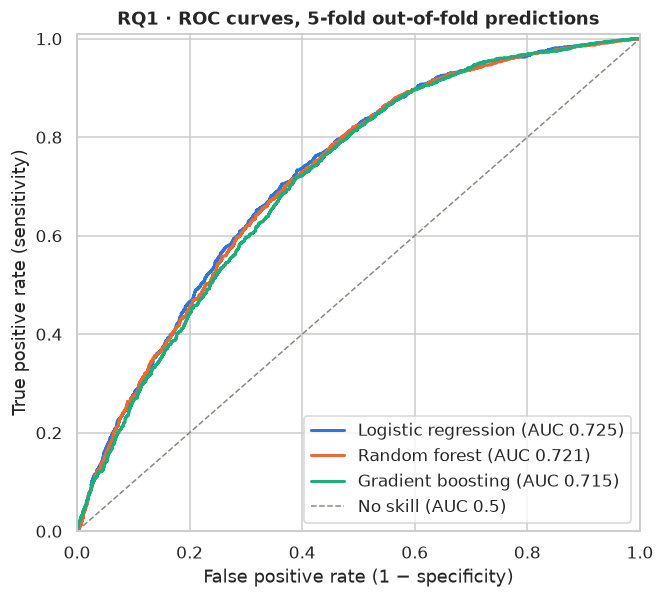

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
for name, p in oof.items():
    fpr, tpr, _ = roc_curve(y, p)
    auc = roc_auc_score(y, p)
    ax.plot(fpr, tpr, lw=2, color=MODEL_COLORS[name], label=f'{name} (AUC {auc:.3f})')
ax.plot([0, 1], [0, 1], ls='--', lw=1, color=GREY, label='No skill (AUC 0.5)')
ax.set_xlabel('False positive rate (1 − specificity)')
ax.set_ylabel('True positive rate (sensitivity)')
ax.set_title('RQ1 · ROC curves, 5-fold out-of-fold predictions')
ax.legend(loc='lower right', frameon=True)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
savefig('22_rq1_roc_curves.png')
plt.show()

## 3.2 Calibration

A model is calibrated if, among patients given a 30% risk, about 30% truly
have the condition. This matters here because the dashboard shows the
predicted risk to the doctor as a number.

Figure saved: figures/23_rq1_calibration.png


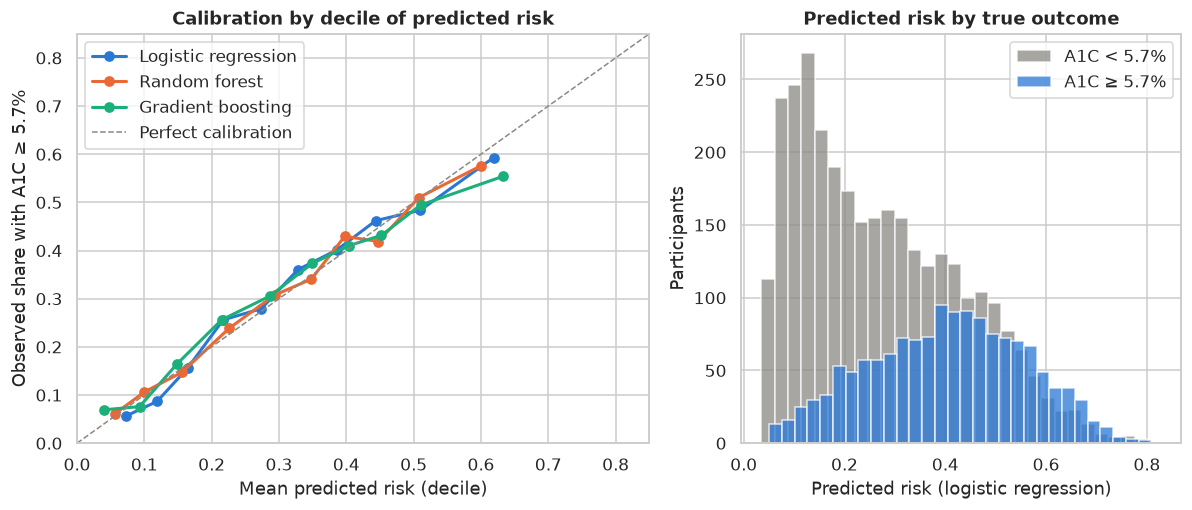

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), gridspec_kw={'width_ratios': [1.3, 1]})
ax = axes[0]
for name, p in oof.items():
    frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy='quantile')
    ax.plot(mean_pred, frac_pos, marker='o', ms=6, lw=2, color=MODEL_COLORS[name], label=name)
ax.plot([0, 1], [0, 1], ls='--', lw=1, color=GREY, label='Perfect calibration')
ax.set_xlabel('Mean predicted risk (decile)')
ax.set_ylabel('Observed share with A1C ≥ 5.7%')
ax.set_title('Calibration by decile of predicted risk')
ax.set_xlim(0, 0.85); ax.set_ylim(0, 0.85)
ax.legend(loc='upper left')

ax = axes[1]
p_lr = oof['Logistic regression']
ax.hist(p_lr[y == 0], bins=30, alpha=0.75, color=GREY, label='A1C < 5.7%')
ax.hist(p_lr[y == 1], bins=30, alpha=0.75, color=MODEL_COLORS['Logistic regression'], label='A1C ≥ 5.7%')
ax.set_xlabel('Predicted risk (logistic regression)')
ax.set_ylabel('Participants')
ax.set_title('Predicted risk by true outcome')
ax.legend()
savefig('23_rq1_calibration.png')
plt.show()

**Interpretation.** All three models track the diagonal closely across
the full risk range — a predicted 40% risk corresponds to roughly 40%
observed. The predicted risk shown on the dashboard can therefore be read at
face value *for the population as a whole* (Section 5.2 shows this does not
hold for every subgroup). The right panel shows why the AUC is moderate:
the two outcome groups overlap heavily between 0.2 and 0.5, exactly where
the clinical threshold has to sit.

## 3.3 Clinical usefulness — decision curve analysis

Decision curve analysis asks: *if the doctor refers everyone above a risk
threshold, is that better than referring everyone, or no one?* Net benefit
counts true positives and penalises false positives by the odds of the
threshold — a doctor who refers at 20% risk is saying one missed case is
worth four unnecessary referrals.

Figure saved: figures/24_rq1_decision_curve.png


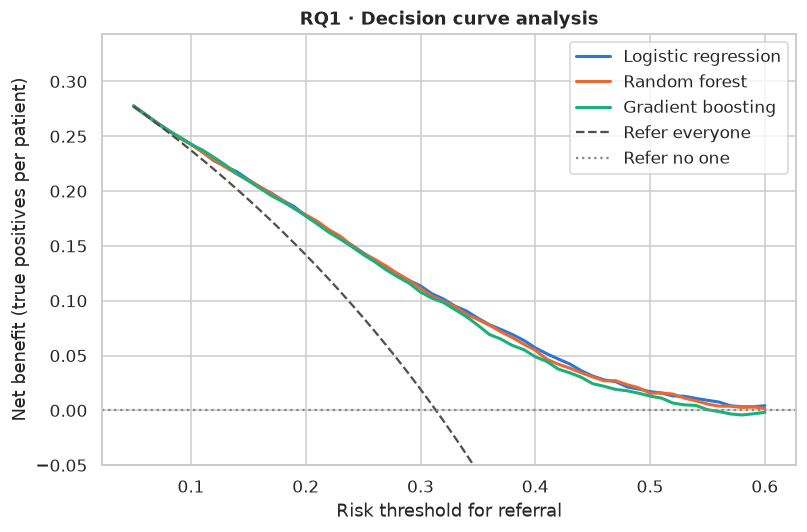

,threshold,refer everyone,Logistic regression,Random forest,Gradient boosting
5,0.10,0.237,0.243,0.243,0.243
10,0.15,0.192,0.210,0.210,0.209
15,0.20,0.142,0.177,0.178,0.177
20,0.25,0.085,0.144,0.143,0.142
25,0.30,0.019,0.113,0.111,0.108
35,0.40,-0.144,0.057,0.055,0.049
45,0.50,-0.373,0.017,0.016,0.013


In [9]:
def net_benefit(y_true, p, thresholds):
    n = len(y_true)
    out = []
    for t in thresholds:
        flag = p >= t
        tp = np.sum(flag & (y_true == 1))
        fp = np.sum(flag & (y_true == 0))
        out.append(tp / n - fp / n * t / (1 - t))
    return np.array(out)

thresholds = np.linspace(0.05, 0.60, 56)
prev = y.mean()
nb_all = prev - (1 - prev) * thresholds / (1 - thresholds)

fig, ax = plt.subplots(figsize=(7.5, 5))
for name, p in oof.items():
    ax.plot(thresholds, net_benefit(y, p, thresholds), lw=2, color=MODEL_COLORS[name], label=name)
ax.plot(thresholds, nb_all, lw=1.5, ls='--', color='#52514e', label='Refer everyone')
ax.axhline(0, lw=1.5, ls=':', color=GREY, label='Refer no one')
ax.set_ylim(-0.05, prev + 0.03)
ax.set_xlabel('Risk threshold for referral')
ax.set_ylabel('Net benefit (true positives per patient)')
ax.set_title('RQ1 · Decision curve analysis')
ax.legend(loc='upper right')
savefig('24_rq1_decision_curve.png')
plt.show()

dca = pd.DataFrame({'threshold': thresholds, 'refer everyone': nb_all,
                    **{name: net_benefit(y, p, thresholds) for name, p in oof.items()}})
dca[dca['threshold'].round(2).isin([0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5])].round(3)

**Interpretation.** Below a threshold of about 10%, the model is no better
than referring everyone — at that point almost everyone would be referred
anyway. Between 15% and 55%, the model adds clear net benefit over both
default strategies. At a 25% threshold, for example, the model's net
benefit (0.144) is 70% higher than referring everyone (0.085): the same
number of cases is found with far fewer unnecessary lab tests. The three
model curves lie on top of each other, confirming the choice of the
simplest model.

## 3.4 Choosing the referral threshold

For screening, missing a case is worse than an extra lab test. The
threshold is set so that the model catches **at least 80% of cases**
(sensitivity ≥ 0.80). Because the threshold is picked on the same
out-of-fold predictions it is evaluated on, its sensitivity is very slightly
optimistic; with 1,446 positives this effect is negligible.

The **Youden** threshold (maximising sensitivity + specificity) is shown for
comparison.

In [10]:
def metrics_at(y_true, p, t):
    y_true = np.asarray(y_true); flag = np.asarray(p) >= t
    tp = int(np.sum(flag & (y_true == 1))); fn = int(np.sum(~flag & (y_true == 1)))
    tn = int(np.sum(~flag & (y_true == 0))); fp = int(np.sum(flag & (y_true == 0)))
    return {'TP': tp, 'FN': fn, 'TN': tn, 'FP': fp,
            'sensitivity': tp / (tp + fn) if tp + fn else np.nan,
            'specificity': tn / (tn + fp) if tn + fp else np.nan,
            'PPV': tp / (tp + fp) if tp + fp else np.nan,
            'NPV': tn / (tn + fn) if tn + fn else np.nan,
            'referred share': flag.mean()}

fpr, tpr, thr = roc_curve(y, p_lr)
THRESHOLD = float(thr[np.argmax(tpr >= TARGET_SENSITIVITY)])
youden_t = float(thr[np.argmax(tpr - fpr)])

rows = []
for label, t in [('Sensitivity ≥ 80% (chosen)', THRESHOLD), ('Youden', youden_t)]:
    m = metrics_at(y, p_lr, t)
    se_lo, se_hi = wilson(m['TP'], m['TP'] + m['FN'])
    sp_lo, sp_hi = wilson(m['TN'], m['TN'] + m['FP'])
    rows.append({'rule': label, 'threshold': t, **m,
                 'sens 95% CI': f'{se_lo:.3f} – {se_hi:.3f}',
                 'spec 95% CI': f'{sp_lo:.3f} – {sp_hi:.3f}'})
threshold_table = pd.DataFrame(rows)
SENS = threshold_table.loc[0, 'sensitivity']
SPEC = threshold_table.loc[0, 'specificity']
print(f'Chosen threshold: predicted risk ≥ {THRESHOLD:.3f}')
print(f'  sensitivity {SENS:.3f}, specificity {SPEC:.3f}')
threshold_table.round(3)

Chosen threshold: predicted risk ≥ 0.260
  sensitivity 0.800, specificity 0.530


,rule,threshold,TP,FN,TN,FP,sensitivity,specificity,PPV,NPV,referred share,sens 95% CI,spec 95% CI
0,Sensitivity ≥ 80% (chosen),0.260,1157,289,1678,1489,0.800,0.530,0.437,0.853,0.574,0.779 – 0.820,0.512 – 0.547
1,Youden,0.302,1061,385,1928,1239,0.734,0.609,0.461,0.834,0.499,0.710 – 0.756,0.592 – 0.626


**Interpretation.** At the chosen threshold (predicted risk ≥ 26%) the
model catches 80% of cases and refers 57% of patients. Of those referred,
44% truly have A1C ≥ 5.7% (PPV, against a 31% base rate); of those not
referred, 85% are truly negative (NPV). These sensitivity and specificity
values are the inputs to RQ2. The Youden threshold refers fewer people
(50%) but misses one case in four — a poor trade for screening.

## 3.5 What drives the risk? Odds ratios from the logistic model

Refitting the logistic regression on the full sample with `statsmodels`
gives interpretable odds ratios. Continuous predictors are scaled to
clinically meaningful steps.

Figure saved: figures/25_rq1_odds_ratios.png


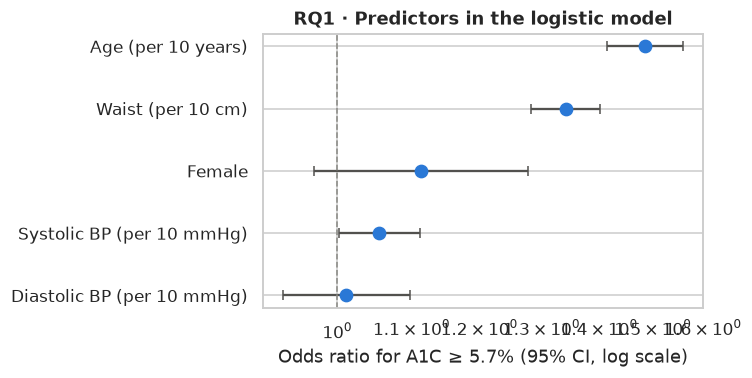

,odds ratio,95% CI low,95% CI high,p-value
Age (per 10 years),1.485,1.414,1.560,0.000
Female,1.114,0.971,1.277,0.124
Waist (per 10 cm),1.341,1.283,1.402,0.000
Systolic BP (per 10 mmHg),1.055,1.002,1.112,0.044
Diastolic BP (per 10 mmHg),1.011,0.932,1.097,0.786


In [11]:
X_or = pd.DataFrame({
    'Age (per 10 years)': df['age'] / 10,
    'Female': df['female'],
    'Waist (per 10 cm)': df['waist'] / 10,
    'Systolic BP (per 10 mmHg)': df['systolic'] / 10,
    'Diastolic BP (per 10 mmHg)': df['diastolic'] / 10,
})
logit = sm.Logit(y, sm.add_constant(X_or)).fit(disp=False)
odds = pd.DataFrame({
    'odds ratio': np.exp(logit.params),
    '95% CI low': np.exp(logit.conf_int()[0]),
    '95% CI high': np.exp(logit.conf_int()[1]),
    'p-value': logit.pvalues,
}).drop(index='const')
odds.to_csv(os.path.join(DATA_PROCESSED, 'rq1_odds_ratios.csv'))

fig, ax = plt.subplots(figsize=(7, 3.6))
order = odds.sort_values('odds ratio').index
ax.errorbar(odds.loc[order, 'odds ratio'], range(len(order)),
            xerr=[odds.loc[order, 'odds ratio'] - odds.loc[order, '95% CI low'],
                  odds.loc[order, '95% CI high'] - odds.loc[order, 'odds ratio']],
            fmt='o', ms=8, color=MODEL_COLORS['Logistic regression'], ecolor='#52514e', capsize=3, lw=1.5)
ax.axvline(1, ls='--', color=GREY, lw=1)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order)
ax.set_xlabel('Odds ratio for A1C ≥ 5.7% (95% CI, log scale)')
ax.set_xscale('log')
ax.set_title('RQ1 · Predictors in the logistic model')
savefig('25_rq1_odds_ratios.png')
plt.show()
odds.round(3)

**Interpretation.** Age is the strongest predictor: each additional decade
raises the odds of dysglycemia by about 49%. Waist is the second: each
extra 10 cm raises the odds by about 34%. Systolic blood pressure adds a
small independent effect (5% per 10 mmHg, borderline significant);
diastolic pressure and sex add nothing once age and waist are known. In
practice the triage rests on two numbers — **age and waist**.

## 3.6 Sensitivity analysis — diabetes-range A1C only

The primary outcome combines prediabetes and diabetes. Restricting the
target to A1C ≥ 6.5% (undiagnosed diabetes) tests whether the
measurements identify the more severe group better.

In [12]:
y_diab = df['diabetes'].values
p_diab = oof_predict(make_logreg(FEATURES), FEATURES, target=y_diab)
auc_d, lo_d, hi_d = bootstrap_auc(y_diab, p_diab)
print(f'Undiagnosed diabetes-range A1C: {y_diab.sum()} cases ({y_diab.mean():.1%})')
print(f'Logistic regression AUC: {auc_d:.3f} (95% CI {lo_d:.3f} – {hi_d:.3f})')

Undiagnosed diabetes-range A1C: 139 cases (3.0%)
Logistic regression AUC: 0.759 (95% CI 0.726 – 0.794)


**Interpretation.** For the narrower target of undiagnosed diabetes-range
A1C the AUC rises to about 0.76: the measurements identify the more
severe cases somewhat better. The wide interval reflects the small number
of cases (139, 3%), which is why the combined prediabetes + diabetes outcome
remains the primary target.

# 4. RQ2 — How reliable is a positive result in each county?

The share of flagged patients who truly have the condition — the **positive
predictive value (PPV)** — depends on how common the condition is locally:

$$\text{PPV} = \frac{\text{sens} \cdot p}{\text{sens} \cdot p + (1-\text{spec})(1-p)}
\qquad
\text{NPV} = \frac{\text{spec} \cdot (1-p)}{\text{spec} \cdot (1-p) + (1-\text{sens}) \cdot p}$$

Sensitivity and specificity come from Section 3.4. The local prevalence
$p$ comes from CDC PLACES.

## 4.1 Converting diagnosed diabetes into screening prevalence

PLACES reports **diagnosed diabetes**; our model targets **A1C ≥ 5.7% among
adults who are not yet diagnosed** (risk R3). The two are linked by a
conversion ratio $r$, estimated from NHANES itself:

$$r = \frac{\text{share of undiagnosed adults with A1C} \ge 5.7\%}{\text{share of all adults with diagnosed diabetes}}$$

and county screening prevalence is $p_c = r \times \text{diagnosed}_c$.
Because $r$ is uncertain (unweighted sample, PLACES is model-based, county
age structures differ), PPV is recomputed for a range of ratios.

In [13]:
clean = pd.read_csv(os.path.join(DATA_PROCESSED, 'nhanes_clean.csv'), index_col='SEQN')
clean = clean[~clean['Pregnancy status at exam'].isin(['Pregnant', 'Cannot ascertain'])]
diagnosed_share = (clean['Doctor told you have diabetes'] == 'Yes').mean()
undiagnosed_dysg = y.mean()
R_NHANES = undiagnosed_dysg / diagnosed_share

RATIOS = {'Low (2.0)': 2.0, f'NHANES estimate ({R_NHANES:.2f})': R_NHANES,
          'Feasibility study (3.1)': 3.1}

print(f'Adults with diagnosed diabetes (NHANES, non-pregnant): {diagnosed_share:.1%}')
print(f'Undiagnosed adults with A1C ≥ 5.7%:                    {undiagnosed_dysg:.1%}')
print(f'Conversion ratio r = {R_NHANES:.2f}')

Adults with diagnosed diabetes (NHANES, non-pregnant): 13.8%
Undiagnosed adults with A1C ≥ 5.7%:                    31.3%
Conversion ratio r = 2.26


In [14]:
places = pd.read_csv(os.path.join(DATA_PROCESSED, 'places_county.csv'), dtype={'locationid': str})
places['fips'] = places['locationid'].str.zfill(5)

def ppv(sens, spec, p):
    return sens * p / (sens * p + (1 - spec) * (1 - p))

def npv(sens, spec, p):
    return spec * (1 - p) / (spec * (1 - p) + (1 - sens) * p)

P_CAP = 0.90
for label, r in RATIOS.items():
    p_c = np.clip(r * places['diagnosed_diabetes_pct'] / 100, 0, P_CAP)
    places[f'prev_{r:.2f}'] = p_c
    places[f'PPV_{r:.2f}'] = ppv(SENS, SPEC, p_c)
    places[f'NPV_{r:.2f}'] = npv(SENS, SPEC, p_c)

R_KEY = f'{R_NHANES:.2f}'
places['screening_prevalence'] = places[f'prev_{R_KEY}']
places['PPV'] = places[f'PPV_{R_KEY}']
places['NPV'] = places[f'NPV_{R_KEY}']

rows = []
for label, r in RATIOS.items():
    col = places[f'PPV_{r:.2f}']; ncol = places[f'NPV_{r:.2f}']
    rows.append({'conversion ratio': label, 'PPV min': col.min(), 'PPV median': col.median(),
                 'PPV max': col.max(), 'PPV spread (pp)': (col.max() - col.min()) * 100,
                 'NPV min': ncol.min(), 'NPV median': ncol.median(), 'NPV max': ncol.max()})
ppv_summary = pd.DataFrame(rows)
ppv_summary.to_csv(os.path.join(DATA_PROCESSED, 'rq2_ppv_summary.csv'), index=False)
ppv_summary.round(3)

,conversion ratio,PPV min,PPV median,PPV max,PPV spread (pp),NPV min,NPV median,NPV max
0,Low (2.0),0.156,0.381,0.668,51.216,0.691,0.880,0.961
1,NHANES estimate (2.26),0.175,0.423,0.730,55.484,0.625,0.860,0.955
2,Feasibility study (3.1),0.234,0.544,0.899,66.580,0.335,0.791,0.937


**Interpretation.** With the NHANES-derived ratio (r = 2.26), the
probability that a positive result is correct ranges from **18% in the
healthiest county to 73% in the county with the highest diabetes burden** —
a 55-percentage-point spread for an identical model and an identical
patient result. The median county sits at 42%. Changing the conversion
ratio shifts the whole distribution (median 38% at r = 2.0, 54% at r = 3.1)
but the spread across counties remains large under every assumption: the
conclusion that location changes the meaning of a positive result does not
depend on the uncertain ratio.

The NPV moves in the opposite direction: in high-burden counties a
negative result is wrong up to one time in three (NPV 0.63), so a negative
triage there should not be taken as reassurance.

In [15]:
# ── Sanity check: does the formula reproduce the NHANES sample itself? ──
check_ppv = ppv(SENS, SPEC, y.mean())
print(f'Formula PPV at NHANES prevalence ({y.mean():.1%}): {check_ppv:.3f}')
print(f'Observed PPV in the sample:                     {threshold_table.loc[0, "PPV"]:.3f}')

Formula PPV at NHANES prevalence (31.3%): 0.437
Observed PPV in the sample:                     0.437


The formula reproduces the observed PPV exactly at the sample prevalence,
confirming that the county figures are computed consistently with RQ1.

## 4.2 PPV across the range of local prevalence

Figure saved: figures/26_rq2_ppv_vs_prevalence.png


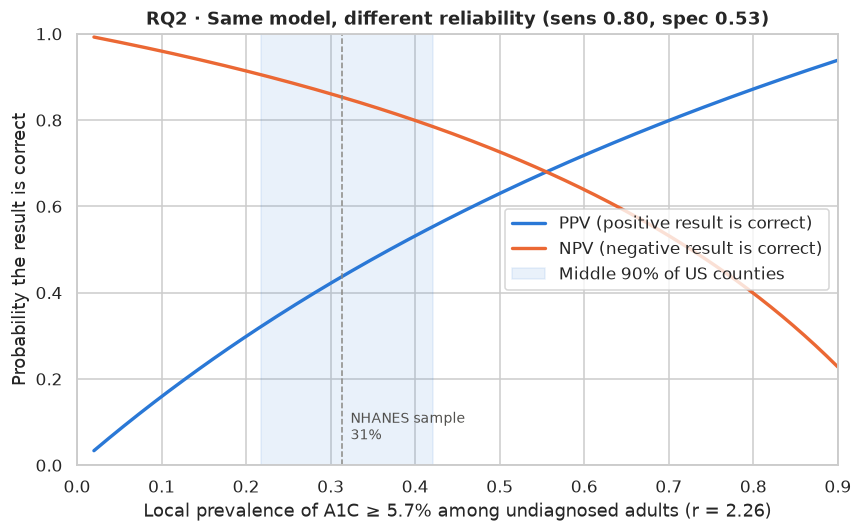

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
grid = np.linspace(0.02, 0.9, 200)
ax.plot(grid, ppv(SENS, SPEC, grid), lw=2.2, color='#2a78d6', label='PPV (positive result is correct)')
ax.plot(grid, npv(SENS, SPEC, grid), lw=2.2, color='#eb6834', label='NPV (negative result is correct)')
lo_q, hi_q = places['screening_prevalence'].quantile([0.05, 0.95])
ax.axvspan(lo_q, hi_q, color='#2a78d6', alpha=0.10, label='Middle 90% of US counties')
ax.axvline(y.mean(), color=GREY, ls='--', lw=1)
ax.text(y.mean() + 0.01, 0.06, f'NHANES sample\n{y.mean():.0%}', color='#52514e', fontsize=9)
ax.set_xlabel(f'Local prevalence of A1C ≥ 5.7% among undiagnosed adults (r = {R_NHANES:.2f})')
ax.set_ylabel('Probability the result is correct')
ax.set_ylim(0, 1.0); ax.set_xlim(0, 0.9)
ax.set_title(f'RQ2 · Same model, different reliability (sens {SENS:.2f}, spec {SPEC:.2f})')
ax.legend(loc='center right')
savefig('26_rq2_ppv_vs_prevalence.png')
plt.show()

## 4.3 County-level distribution and sensitivity to the conversion ratio

Figure saved: figures/27_rq2_ppv_distribution.png


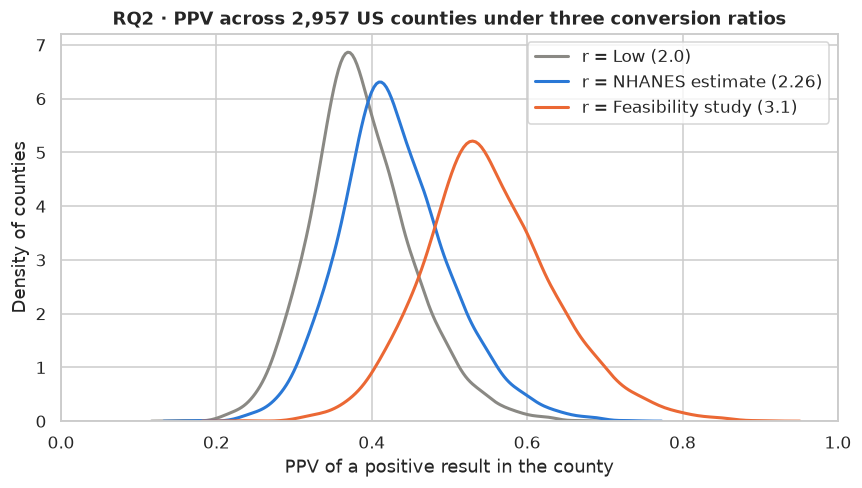

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.6))
colors = ['#8a8984', '#2a78d6', '#eb6834']
for (label, r), c in zip(RATIOS.items(), colors):
    sns.kdeplot(places[f'PPV_{r:.2f}'], ax=ax, lw=2, color=c, label=f'r = {label}', fill=False)
ax.set_xlabel('PPV of a positive result in the county')
ax.set_ylabel('Density of counties')
ax.set_title(f'RQ2 · PPV across {len(places):,} US counties under three conversion ratios')
ax.legend()
ax.set_xlim(0, 1)
savefig('27_rq2_ppv_distribution.png')
plt.show()

Figure saved: figures/28_rq2_ppv_by_state.png


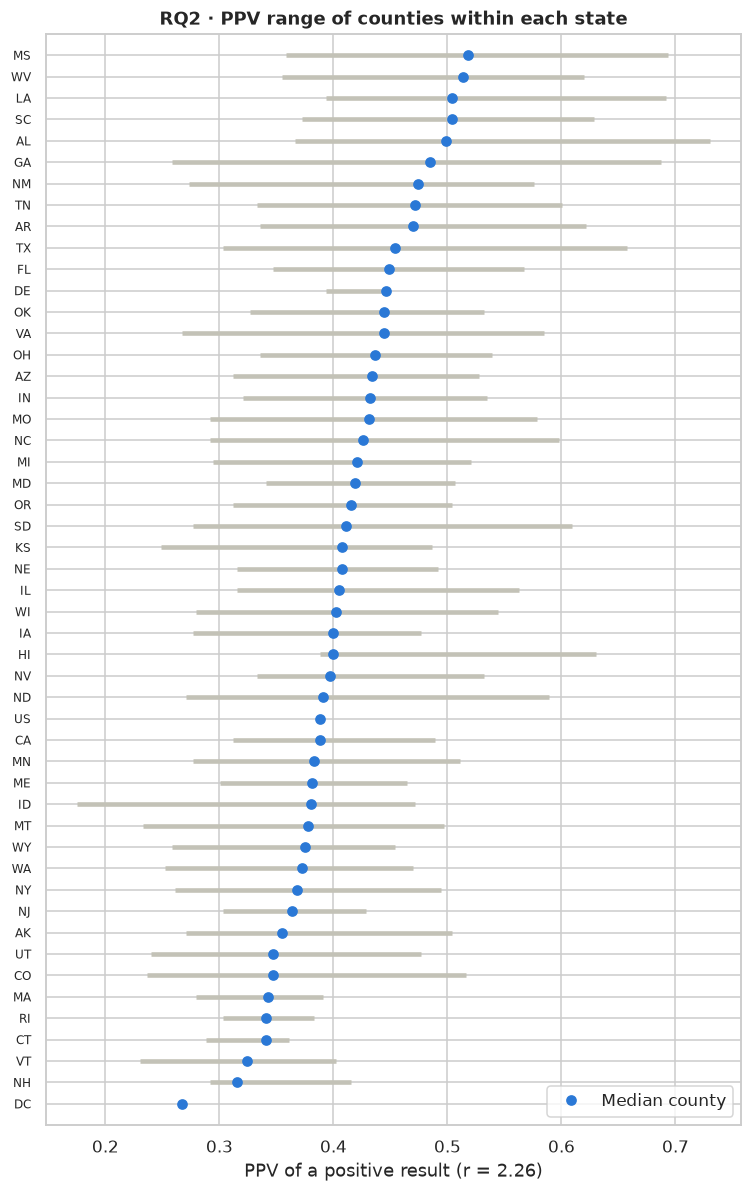

In [18]:
state = (places.groupby('stateabbr')
         .agg(counties=('fips', 'size'), median_PPV=('PPV', 'median'),
              min_PPV=('PPV', 'min'), max_PPV=('PPV', 'max'))
         .sort_values('median_PPV'))

fig, ax = plt.subplots(figsize=(7, 11))
ypos = np.arange(len(state))
ax.hlines(ypos, state['min_PPV'], state['max_PPV'], color='#c3c2b7', lw=3)
ax.plot(state['median_PPV'], ypos, 'o', ms=6, color='#2a78d6', label='Median county')
ax.set_yticks(ypos); ax.set_yticklabels(state.index, fontsize=8)
ax.set_xlabel(f'PPV of a positive result (r = {R_NHANES:.2f})')
ax.set_title('RQ2 · PPV range of counties within each state')
ax.legend(loc='lower right')
ax.set_ylim(-1, len(state))
savefig('28_rq2_ppv_by_state.png')
plt.show()

**Interpretation.** Variation *within* states is often as large as
variation *between* them. A state-level adjustment would therefore not be
enough — the dashboard works at county level.

In [19]:
cols = ['locationname', 'stateabbr', 'diagnosed_diabetes_pct', 'screening_prevalence', 'PPV', 'NPV']
print('Lowest PPV counties')
print(places.nsmallest(5, 'PPV')[cols].round(3).to_string(index=False))
print()
print('Highest PPV counties')
print(places.nlargest(5, 'PPV')[cols].round(3).to_string(index=False))

Lowest PPV counties
locationname stateabbr  diagnosed_diabetes_pct  screening_prevalence   PPV   NPV
     Madison        ID                     4.9                 0.111 0.175 0.955
  Chittenden        VT                     6.6                 0.149 0.230 0.938
    Gallatin        MT                     6.7                 0.152 0.233 0.937
     Douglas        CO                     6.8                 0.154 0.237 0.936
        Utah        UT                     6.9                 0.156 0.240 0.935

Highest PPV counties
locationname stateabbr  diagnosed_diabetes_pct  screening_prevalence   PPV   NPV
      Greene        AL                    27.1                 0.614 0.730 0.625
     Sharkey        MS                    25.2                 0.571 0.694 0.666
      Tensas        LA                    25.1                 0.568 0.692 0.668
    Randolph        GA                    24.9                 0.564 0.688 0.672
   Humphreys        MS                    24.7                 0.55

## 4.4 County map

The map is drawn with Plotly from the US county boundaries published in the
Plotly datasets repository. If the boundary file cannot be downloaded, the
cell is skipped and the analysis above is unaffected. Kentucky and
Pennsylvania appear grey because the 2023 PLACES county release contains no
estimates for them; Connecticut is grey because PLACES uses its new
planning-region codes, which the boundary file predates.

In [20]:
try:
    import plotly.express as px
    from urllib.request import urlopen
    GEO_URL = 'https://raw.githubusercontent.com/plotly/datasets/master/geojson-counties-fips.json'
    with urlopen(GEO_URL, timeout=30) as resp:
        counties_geo = json.load(resp)
    fig_map = px.choropleth(
        places, geojson=counties_geo, locations='fips', color='PPV',
        color_continuous_scale='Blues', range_color=(0.3, 0.9), scope='usa',
        hover_name='locationname',
        hover_data={'stateabbr': True, 'diagnosed_diabetes_pct': ':.1f', 'PPV': ':.2f', 'NPV': ':.2f', 'fips': False},
        labels={'PPV': 'PPV', 'diagnosed_diabetes_pct': 'Diagnosed diabetes (%)', 'stateabbr': 'State'},
        title=f'RQ2 · Probability that a positive triage result is correct, by county (r = {R_NHANES:.2f})')
    fig_map.update_traces(marker_line_width=0)
    fig_map.update_layout(margin=dict(l=0, r=0, t=50, b=0))
    fig_map.write_html(os.path.join(FIGURES, '29_rq2_ppv_county_map.html'), include_plotlyjs='cdn')
    try:
        fig_map.write_image(os.path.join(FIGURES, '29_rq2_ppv_county_map.png'), width=1100, height=650, scale=2)
        print('Figure saved: figures/29_rq2_ppv_county_map.png (+ interactive .html)')
    except Exception as e:
        print(f'Static export skipped ({type(e).__name__}); interactive .html saved.')
    print('Open figures/29_rq2_ppv_county_map.html in a browser for the interactive version.')
except Exception as e:
    print(f'County map skipped: {type(e).__name__}: {e}')

Figure saved: figures/29_rq2_ppv_county_map.png (+ interactive .html)
Open figures/29_rq2_ppv_county_map.html in a browser for the interactive version.


# 5. RQ3 — Does the model work equally well for all patients?

The same out-of-fold predictions and the same referral threshold are
evaluated within each subgroup. Two questions are kept apart:

- **Missed referrals** — sensitivity: of the people in this group who have
  dysglycemia, what share does a uniform threshold flag?
- **Ranking ability** — AUC: within this group, do the measurements still
  separate cases from non-cases?

Groups with fewer than 50 positive cases are reported but not interpreted
(risk R4).

In [21]:
df['p_lr'] = p_lr
df['flag'] = (p_lr >= THRESHOLD).astype(int)

# First look with groupby/agg: how often is each group referred, and how common is the condition?
for col in ['sex', 'race', 'age_band']:
    print(df.groupby(col, observed=True).agg(
        participants=('dysglycemia', 'size'),
        cases=('dysglycemia', 'sum'),
        prevalence=('dysglycemia', 'mean'),
        referred_share=('flag', 'mean'),
    ).round(3).to_string())
    print()

def subgroup_table(col, order=None):
    rows = []
    groups = order if order is not None else sorted(df[col].dropna().unique())
    for g in groups:
        d = df[df[col] == g]
        yt, pp = d['dysglycemia'].values, d['p_lr'].values
        m = metrics_at(yt, pp, THRESHOLD)
        auc, alo, ahi = bootstrap_auc(yt, pp, n=500)
        se_lo, se_hi = wilson(m['TP'], m['TP'] + m['FN'])
        sp_lo, sp_hi = wilson(m['TN'], m['TN'] + m['FP'])
        rows.append({
            'dimension': col, 'group': g, 'n': len(d), 'positives': int(yt.sum()),
            'prevalence': yt.mean(), 'mean predicted risk': pp.mean(),
            'sensitivity': m['sensitivity'], 'sens low': se_lo, 'sens high': se_hi,
            'specificity': m['specificity'], 'spec low': sp_lo, 'spec high': sp_hi,
            'PPV': m['PPV'], 'AUC': auc, 'AUC low': alo, 'AUC high': ahi,
            'missed cases (FN)': m['FN'],
            'interpretable': yt.sum() >= MIN_POSITIVES,
        })
    return pd.DataFrame(rows)

RACE_ORDER = ['Non-Hispanic White', 'Non-Hispanic Black', 'Mexican American',
              'Other Hispanic', 'Non-Hispanic Asian', 'Other Race - Including Multi-Racial']
subgroups = pd.concat([
    subgroup_table('sex', ['Female', 'Male']),
    subgroup_table('race', RACE_ORDER),
    subgroup_table('age_band', AGE_ORDER),
], ignore_index=True)
subgroups.to_csv(os.path.join(DATA_PROCESSED, 'rq3_subgroup_performance.csv'), index=False)

show = subgroups[['dimension', 'group', 'n', 'positives', 'prevalence', 'mean predicted risk',
                  'sensitivity', 'specificity', 'PPV', 'AUC', 'interpretable']]
show.round(3)

        participants  cases  prevalence  referred_share
sex                                                    
Female          2537    782       0.308           0.568
Male            2076    664       0.320           0.581

                                     participants  cases  prevalence  referred_share
race                                                                                
Mexican American                              300    113       0.377           0.420
Non-Hispanic Asian                            258     90       0.349           0.341
Non-Hispanic Black                            476    218       0.458           0.559
Non-Hispanic White                           2837    783       0.276           0.642
Other Hispanic                                463    151       0.326           0.428
Other Race - Including Multi-Racial           279     91       0.326           0.530

          participants  cases  prevalence  referred_share
age_band                            

,dimension,group,n,positives,prevalence,mean predicted risk,sensitivity,specificity,PPV,AUC,interpretable
0,sex,Female,2537,782,0.308,0.308,0.822,0.546,0.447,0.743,True
1,sex,Male,2076,664,0.320,0.320,0.774,0.510,0.426,0.704,True
2,race,Non-Hispanic White,2837,783,0.276,0.340,0.912,0.462,0.392,0.760,True
3,race,Non-Hispanic Black,476,218,0.458,0.300,0.665,0.531,0.545,0.652,True
4,race,Mexican American,300,113,0.377,0.251,0.628,0.706,0.563,0.761,True
5,race,Other Hispanic,463,151,0.326,0.264,0.709,0.708,0.540,0.761,True
6,race,Non-Hispanic Asian,258,90,0.349,0.222,0.567,0.780,0.580,0.770,True
7,race,Other Race - Including Multi-Racial,279,91,0.326,0.302,0.758,0.580,0.466,0.718,True
8,age_band,20-39,1283,148,0.115,0.138,0.169,0.934,0.250,0.676,True
9,age_band,40-54,985,277,0.281,0.251,0.567,0.702,0.427,0.682,True


All 12 subgroups have at least 50 positive cases, so all are interpreted.

## 5.1 Forest plot — sensitivity and AUC by subgroup

Figure saved: figures/30_rq3_subgroup_forest.png


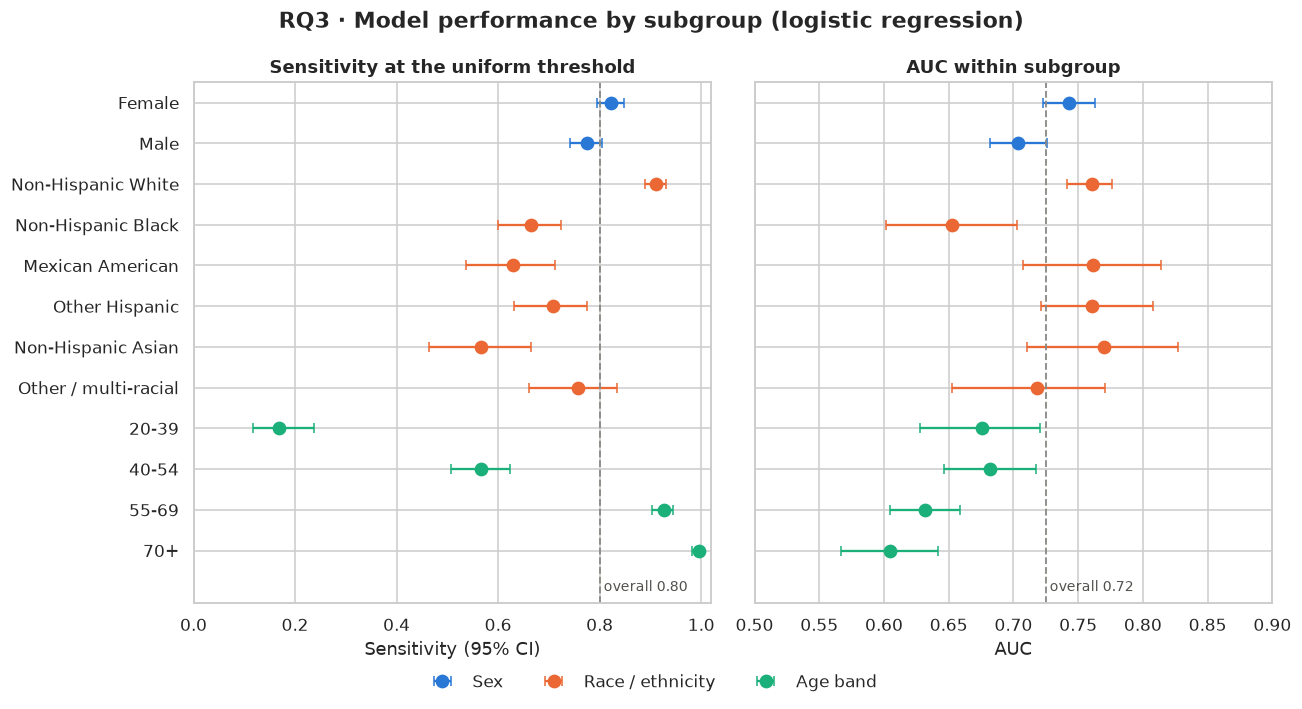

In [22]:
plot_df = subgroups.copy()
plot_df['label'] = plot_df['group'].replace({'Other Race - Including Multi-Racial': 'Other / multi-racial'})
dim_names = {'sex': 'Sex', 'race': 'Race / ethnicity', 'age_band': 'Age band'}

fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), sharey=True)
ypos = np.arange(len(plot_df))[::-1]
for ax, (metric, lo, hi, overall, title) in zip(axes, [
        ('sensitivity', 'sens low', 'sens high', SENS, 'Sensitivity at the uniform threshold'),
        ('AUC', 'AUC low', 'AUC high', roc_auc_score(y, p_lr), 'AUC within subgroup')]):
    for dim, c in zip(['sex', 'race', 'age_band'], ['#2a78d6', '#eb6834', '#1baf7a']):
        m = plot_df['dimension'] == dim
        ax.errorbar(plot_df.loc[m, metric], ypos[m.values],
                    xerr=[plot_df.loc[m, metric] - plot_df.loc[m, lo], plot_df.loc[m, hi] - plot_df.loc[m, metric]],
                    fmt='o', ms=8, color=c, ecolor=c, capsize=3, lw=1.5, label=dim_names[dim])
    ax.axvline(overall, ls='--', color=GREY, lw=1.2)
    ax.text(overall, -0.9, f' overall {overall:.2f}', color='#52514e', fontsize=9, va='center')
    ax.set_title(title)
    ax.set_xlabel(metric if metric == 'AUC' else 'Sensitivity (95% CI)')
axes[0].set_yticks(ypos); axes[0].set_yticklabels(plot_df['label'])
axes[0].set_xlim(0, 1.02); axes[1].set_xlim(0.5, 0.9)
axes[0].set_ylim(-1.3, len(plot_df) - 0.5)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('RQ3 · Model performance by subgroup (logistic regression)', fontweight='bold')
savefig('30_rq3_subgroup_forest.png')
plt.show()

**Interpretation.**

- **Sex.** Small difference: sensitivity 0.82 for women and 0.77 for men,
  with overlapping intervals.
- **Race / ethnicity.** The uniform threshold catches 91% of cases among
  White adults but only **57% among Asian**, 63% among Mexican American and
  67% among Black adults. These are large, statistically clear gaps. Yet the
  AUC (right panel) is similar for most groups (0.72–0.77): the
  measurements *rank* patients within these groups just as well. The
  problem is the **level** of predicted risk, not the ranking — see 5.2.
  The exception is Black adults, whose AUC is also lower (0.65): the
  backpack measurements carry less information for this group.
- **Age.** The threshold behaves almost like an age cut-off: it catches
  99% of cases over 70 but only 17% of cases aged 20–39. Within-band AUCs
  are low (0.60–0.68) because most of the model's discrimination comes
  from age itself.

## 5.2 Calibration within subgroups

If a group's observed prevalence is higher than the model's average
predicted risk, the model systematically underestimates risk for that group —
and a uniform threshold will miss more of its cases.

Figure saved: figures/31_rq3_subgroup_calibration.png


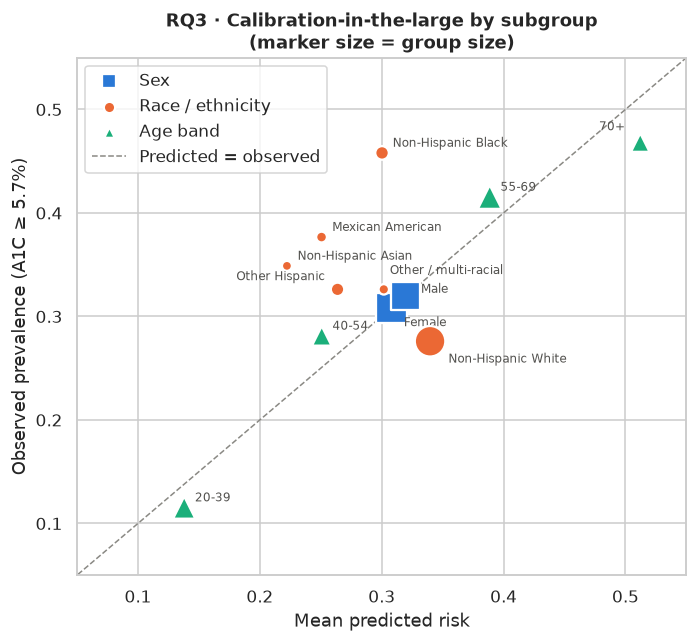

In [23]:
LABEL_OFFSETS = {
    'Female': (8, -12, 'left'), 'Male': (10, 2, 'left'),
    'Other Hispanic': (-8, 6, 'right'), 'Other / multi-racial': (4, 10, 'left'),
    'Non-Hispanic White': (12, -14, 'left'), '70+': (-10, 8, 'right'),
}
fig, ax = plt.subplots(figsize=(6.5, 6))
for dim, c, mk in zip(['sex', 'race', 'age_band'], ['#2a78d6', '#eb6834', '#1baf7a'], ['s', 'o', '^']):
    d = plot_df[plot_df['dimension'] == dim]
    ax.scatter(d['mean predicted risk'], d['prevalence'], s=np.clip(d['n'] / 6, 40, 400),
               color=c, marker=mk, edgecolor='white', lw=1.5, label=dim_names[dim], zorder=3)
    for _, r in d.iterrows():
        dx, dy, ha = LABEL_OFFSETS.get(r['label'], (7, 4, 'left'))
        ax.annotate(r['label'], (r['mean predicted risk'], r['prevalence']),
                    xytext=(dx, dy), textcoords='offset points', fontsize=8, color='#52514e', ha=ha)
ax.plot([0, 0.6], [0, 0.6], ls='--', color=GREY, lw=1, label='Predicted = observed')
ax.set_xlim(0.05, 0.55); ax.set_ylim(0.05, 0.55)
ax.set_xlabel('Mean predicted risk')
ax.set_ylabel('Observed prevalence (A1C ≥ 5.7%)')
ax.set_title('RQ3 · Calibration-in-the-large by subgroup\n(marker size = group size)')
ax.legend(loc='upper left', markerscale=0.5)
savefig('31_rq3_subgroup_calibration.png')
plt.show()

**Interpretation.** This figure explains the sensitivity gaps. White
adults sit *below* the diagonal (predicted 34%, observed 28%) — the model
over-estimates their risk, so the threshold flags them generously. Every
other race group sits *above* the diagonal: Black adults are predicted at
30% but observed at 46%, Asian adults at 22% vs 35%. Because the model
is fitted on a sample that is 61% White, its average relationship between
waist, age and A1C is the White one, and it systematically under-estimates
risk for the other groups. Asian adults are the clearest case: at the
same A1C, they tend to have smaller waists, so a waist-based score misses
them.

## 5.3 Age-adjusted comparison

Age drives prevalence most strongly, and the race groups have different age
profiles. A difference in sensitivity between race groups could therefore
be an age effect. Two checks separate them:

1. **Sensitivity by race within age bands** — a heatmap of the same metric
   with age held roughly constant.
2. **Missed-case regression** — among true cases only, a logistic
   regression of *being missed* on race, adjusted for age. An odds ratio
   above 1 means cases in that group are more likely to be missed than
   White cases of the same age.

Figure saved: figures/32_rq3_sensitivity_race_by_age.png


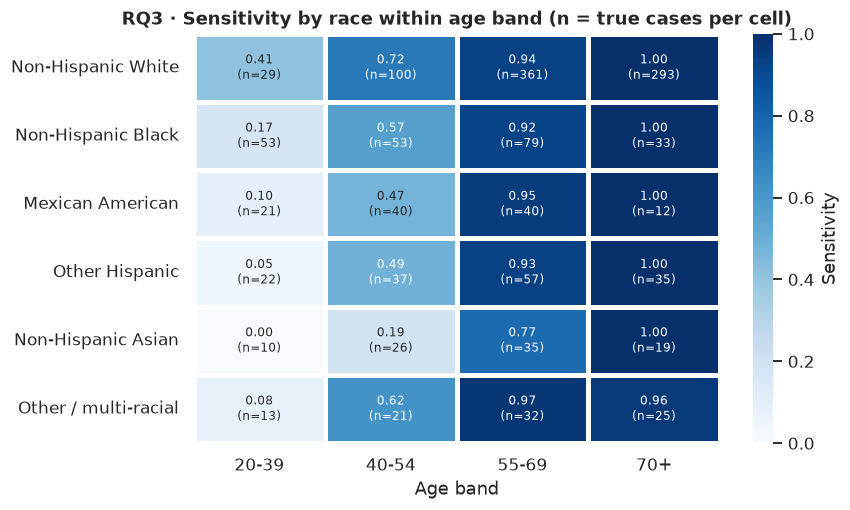

In [24]:
cases = df[df['dysglycemia'] == 1].copy()
cases['missed'] = 1 - cases['flag']
heat = (cases.groupby(['race', 'age_band'], observed=True)
        .agg(sens=('flag', 'mean'), n=('flag', 'size')).reset_index())
sens_mat = heat.pivot(index='race', columns='age_band', values='sens').reindex(RACE_ORDER)
n_mat = heat.pivot(index='race', columns='age_band', values='n').reindex(RACE_ORDER)
annot = sens_mat.map(lambda v: '' if pd.isna(v) else f'{v:.2f}') + '\n(n=' + n_mat.fillna(0).astype(int).astype(str) + ')'

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.heatmap(sens_mat, annot=annot, fmt='', cmap='Blues', vmin=0, vmax=1,
            cbar_kws={'label': 'Sensitivity'}, linewidths=2, linecolor='white', ax=ax,
            annot_kws={'fontsize': 8})
ax.set_yticklabels([l.replace('Other Race - Including Multi-Racial', 'Other / multi-racial') for l in sens_mat.index], rotation=0)
ax.set_xlabel('Age band'); ax.set_ylabel('')
ax.set_title('RQ3 · Sensitivity by race within age band (n = true cases per cell)')
savefig('32_rq3_sensitivity_race_by_age.png')
plt.show()

In [25]:
X_miss = pd.get_dummies(cases['race'], drop_first=False).astype(float)
X_miss = X_miss.drop(columns='Non-Hispanic White')
X_miss['Age (per 10 years)'] = cases['age'] / 10
X_miss['Female'] = cases['female']
miss_model = sm.Logit(cases['missed'].values, sm.add_constant(X_miss)).fit(disp=False)
miss_or = pd.DataFrame({
    'odds ratio of being missed': np.exp(miss_model.params),
    '95% CI low': np.exp(miss_model.conf_int()[0]),
    '95% CI high': np.exp(miss_model.conf_int()[1]),
    'p-value': miss_model.pvalues,
}).drop(index='const')
miss_or.to_csv(os.path.join(DATA_PROCESSED, 'rq3_missed_case_odds.csv'))
print(f'Cases: {len(cases):,}, missed at the uniform threshold: {cases["missed"].sum():,} ({cases["missed"].mean():.1%})')
print('Reference group: Non-Hispanic White')
miss_or.round(3)

Cases: 1,446, missed at the uniform threshold: 289 (20.0%)
Reference group: Non-Hispanic White


,odds ratio of being missed,95% CI low,95% CI high,p-value
Mexican American,2.072,1.140,3.766,0.017
Non-Hispanic Asian,8.359,4.328,16.146,0.000
Non-Hispanic Black,1.454,0.862,2.453,0.160
Other Hispanic,2.525,1.423,4.480,0.002
Other Race - Including Multi-Racial,1.490,0.698,3.179,0.303
Age (per 10 years),0.214,0.179,0.256,0.000
Female,0.763,0.529,1.102,0.149


**Interpretation.** The heatmap shows that the race gap is **not** an age
artefact: within every age band below 70, White cases are caught most
often. In the regression, after adjusting for age and sex, a case in an
Asian adult is **8.4 times** as likely to be missed as a White case of the
same age (95% CI 4.3 – 16.1); Other Hispanic (2.5×) and Mexican American
(2.1×) cases are also significantly more likely to be missed. For Black
adults the adjusted odds ratio (1.45) is not statistically significant:
part of their lower crude sensitivity is explained by their younger age
profile, but their under-calibration (5.2) remains.

## 5.4 Does telling the model the patient's group close the gap?

A backpack doctor knows the patient's self-reported race/ethnicity. Adding
it as a predictor lets the model shift the baseline risk per group. This is
a debated practice in clinical prediction, so it is tested here as an
option rather than adopted: the question is only whether it would reduce
missed referrals.

In [26]:
race_dummies = pd.get_dummies(df['race'], prefix='race', drop_first=True).astype(int)
race_cols = list(race_dummies.columns)
df = df.join(race_dummies)
FEATURES_RACE = FEATURES + race_cols

def make_logreg_race(features):
    numeric = [f for f in features if f != 'female' and not f.startswith('race_')]
    pre = ColumnTransformer([('num', StandardScaler(), numeric)], remainder='passthrough')
    return Pipeline([('pre', pre), ('clf', LogisticRegression(max_iter=1000, C=1e4))])

p_race = oof_predict(make_logreg_race(FEATURES_RACE), FEATURES_RACE)
auc_r, lo_r, hi_r = bootstrap_auc(y, p_race)
fpr_r, tpr_r, thr_r = roc_curve(y, p_race)
THRESHOLD_RACE = float(thr_r[np.argmax(tpr_r >= TARGET_SENSITIVITY)])

rows = []
for g in RACE_ORDER:
    m = (df['race'] == g).values
    a = metrics_at(y[m], p_lr[m], THRESHOLD)
    b = metrics_at(y[m], p_race[m], THRESHOLD_RACE)
    rows.append({'group': g, 'positives': int(y[m].sum()),
                 'sensitivity — base model': a['sensitivity'],
                 'sensitivity — with race': b['sensitivity'],
                 'specificity — base model': a['specificity'],
                 'specificity — with race': b['specificity']})
race_fix = pd.DataFrame(rows)
race_fix.to_csv(os.path.join(DATA_PROCESSED, 'rq3_with_race_comparison.csv'), index=False)
print(f'Overall AUC with race: {auc_r:.3f} (95% CI {lo_r:.3f} – {hi_r:.3f}) vs {roc_auc_score(y, p_lr):.3f} without')
print(f'Threshold for 80% overall sensitivity: {THRESHOLD_RACE:.3f}')
race_fix.round(3)

Overall AUC with race: 0.752 (95% CI 0.737 – 0.767) vs 0.725 without
Threshold for 80% overall sensitivity: 0.271


,group,positives,sensitivity — base model,sensitivity — with race,specificity — base model,specificity — with race
0,Non-Hispanic White,783,0.912,0.774,0.462,0.630
1,Non-Hispanic Black,218,0.665,0.858,0.531,0.337
2,Mexican American,113,0.628,0.832,0.706,0.481
3,Other Hispanic,151,0.709,0.788,0.708,0.619
4,Non-Hispanic Asian,90,0.567,0.889,0.780,0.571
5,Other Race - Including Multi-Racial,91,0.758,0.780,0.580,0.564


Figure saved: figures/33_rq3_with_race_comparison.png


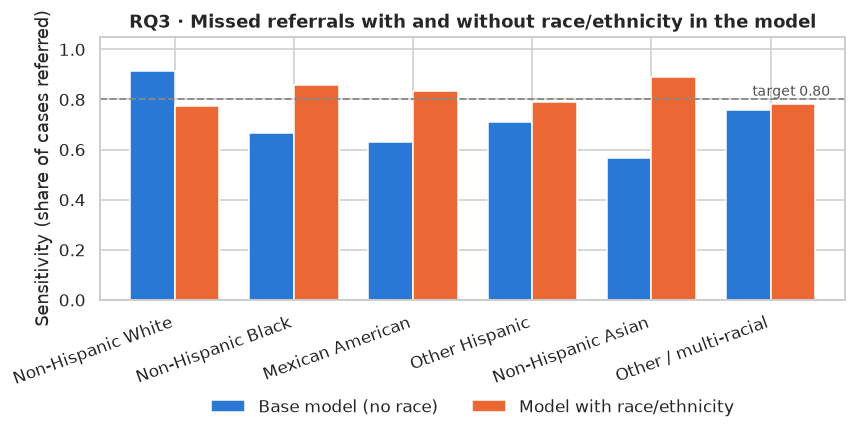

In [27]:
bar_df = race_fix.set_index('group')[['sensitivity — base model', 'sensitivity — with race']]
bar_df.index = bar_df.index.str.replace('Other Race - Including Multi-Racial', 'Other / multi-racial')
bar_df.columns = ['Base model (no race)', 'Model with race/ethnicity']
ax = bar_df.plot.bar(figsize=(8, 4.4), color=['#2a78d6', '#eb6834'], width=0.75, edgecolor='white', rot=20)
ax.axhline(TARGET_SENSITIVITY, ls='--', color=GREY, lw=1.2)
ax.text(len(bar_df) - 0.5, TARGET_SENSITIVITY + 0.015, 'target 0.80', ha='right', fontsize=9, color='#52514e')
ax.set_xticklabels(bar_df.index, ha='right')
ax.set_xlabel('')
ax.set_ylabel('Sensitivity (share of cases referred)')
ax.set_ylim(0, 1.05)
ax.set_title('RQ3 · Missed referrals with and without race/ethnicity in the model')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
savefig('33_rq3_with_race_comparison.png')
plt.show()

**Interpretation.** Adding race/ethnicity raises the overall AUC from
0.725 to 0.752 and largely closes the sensitivity gap: every group now
lands between 0.77 and 0.89, against 0.57–0.91 before. The cost is moved,
not removed — specificity falls for the groups that gain sensitivity
(e.g. Black adults from 0.53 to 0.34), meaning more referrals that turn out
negative in those groups, while White adults get fewer unnecessary
referrals. For a screening tool whose purpose is to avoid missed cases,
this is the better trade, but the choice is clinical and ethical, not only
statistical. The project therefore keeps the race-free model as primary and
uses the dashboard to **show the doctor the subgroup's sensitivity** rather
than silently adjusting the score.

# 6. Exports for the dashboard

The dashboard (`visualizer.py`) needs three things: the fitted model, the
county reliability table, and the subgroup performance table. The model is
refitted on the full analytic sample — the cross-validated figures above
remain the honest estimate of its performance.

In [28]:
final_model = make_logreg(FEATURES).fit(df[FEATURES], y)
joblib.dump({'model': final_model, 'features': FEATURES, 'threshold': THRESHOLD,
             'sensitivity': SENS, 'specificity': SPEC, 'conversion_ratio': R_NHANES,
             'trained_on': f'NHANES 2021-2023, n={len(df)}'},
            os.path.join(MODELS, 'triage_model.joblib'))

county_out = places[['fips', 'locationname', 'stateabbr', 'diagnosed_diabetes_pct',
                     'screening_prevalence', 'PPV', 'NPV']
                    + [c for c in places.columns if c.startswith(('PPV_', 'NPV_'))]]
county_out.to_csv(os.path.join(DATA_PROCESSED, 'rq2_county_ppv.csv'), index=False)

print('Exported:')
for f in [f'{MODELS}/triage_model.joblib', f'{DATA_PROCESSED}/rq2_county_ppv.csv',
          f'{DATA_PROCESSED}/rq3_subgroup_performance.csv']:
    print(f'  {f}  ({os.path.getsize(f) / 1024:.0f} KB)')

# Example: one patient through the exported model
example = pd.DataFrame([{'age': 58, 'female': 1, 'systolic': 138, 'diastolic': 84, 'waist': 102}])
risk = final_model.predict_proba(example[FEATURES])[0, 1]
print(f'\nExample patient risk: {risk:.1%} → {"refer" if risk >= THRESHOLD else "no referral"} (threshold {THRESHOLD:.1%})')

Exported:
  models/triage_model.joblib  (3 KB)
  data/processed/rq2_county_ppv.csv  (560 KB)
  data/processed/rq3_subgroup_performance.csv  (3 KB)

Example patient risk: 37.6% → refer (threshold 26.0%)


# 7. Summary of findings

**RQ1 — How well do backpack measurements predict dysglycemia?**
Moderately well. A five-variable logistic regression (age, sex, waist,
first systolic and diastolic reading) reaches a cross-validated **AUC of
0.725** (95% CI 0.709–0.739), is well calibrated, and offers clear net
benefit over "refer everyone" for referral thresholds between about 15%
and 55%. Random forest and gradient boosting do no better, and BMI adds
nothing over waist. At a threshold of 26% predicted risk, the model catches
80% of cases while referring 57% of patients. Age and waist carry almost
all of the signal.

**RQ2 — Of the patients flagged, what fraction truly have the condition?**
It depends strongly on where the doctor works. With identical sensitivity
and specificity, the PPV ranges from **18% to 73%** across 2,957 US
counties (median 42%), and the spread stays above 50 percentage points
under every conversion assumption tested. In high-burden counties a
negative result is also less reassuring (NPV down to 0.63).

**RQ3 — Does the model work equally well for all patients?**
No. At a uniform threshold, sensitivity is 0.91 for White adults but
0.57–0.71 for Asian, Mexican American, Black and Other Hispanic adults.
The model ranks patients well within most groups (similar AUC); the problem
is that it under-estimates the *level* of risk for every non-White group,
because the same waist and age carry higher risk in those groups. The gap
persists after adjusting for age (Asian cases 8.4× more likely to be
missed). Young adults are also largely missed (sensitivity 0.17 at 20–39).
Adding race/ethnicity to the model closes most of the gap at the cost of
more false positives in the affected groups.

**Limitations.**
- NHANES sampling weights are not applied (see notebook 01), so
  performance figures describe this sample rather than the US population.
- Prevalence conversion from PLACES (diagnosed diabetes) to the model's
  target relies on a single national ratio; county age structure is not
  modelled.
- A1C is an imperfect reference standard (risk R1); results describe
  agreement with A1C, not with a full diagnostic work-up.
- No external validation: performance outside the US population is
  unknown — relevant for any real "backpack" deployment.

**Outlook.** Group-specific thresholds or recalibration, adding a
finger-stick glucose (still backpack-portable), and validation on a second
NHANES cycle are the natural next steps.